In [3]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [19]:
X_train_full = np.loadtxt('mnist_training.csv', delimiter=',')
y_train_full = np.loadtxt('mnist_train_class.csv')

X_test = np.loadtxt('mnist_testing.csv', delimiter=',')
y_test = np.loadtxt('mnist_test_class.csv')

print("training images:", X_train_full.shape)
print("training labels:", y_train_full.shape)
print("test images:", X_test.shape)
print("test labels:", y_test.shape)

training images: (60000, 784)
training labels: (60000,)
test images: (10000, 784)
test labels: (10000,)


In [20]:
X_train_full = X_train_full / 255.0
X_test = X_test / 255.0

X_train, X_unused, y_train, y_unused = train_test_split(
    X_train_full,
    y_train_full,
    train_size=6000,
    stratify=y_train_full,
    random_state=42
)

print("number of images we are actually training on:", X_train.shape[0])

number of images we are actually training on: 6000


In [21]:
model = SVC(kernel='linear', C=1.0)
model.fit(X_train, y_train)

print("number of support vectors:", model.support_vectors_.shape[0])
print("out of these many training images:", X_train.shape[0])

number of support vectors: 2027
out of this many training images: 6000


In [26]:
y_predicted = model.predict(X_test)

accuracy = accuracy_score(y_test, y_predicted)
print("accuracy on the test set:", accuracy)

print(classification_report(y_test, y_predicted))

accuracy on the test set: 0.9151
              precision    recall  f1-score   support

         0.0       0.94      0.97      0.96       980
         1.0       0.96      0.98      0.97      1135
         2.0       0.91      0.89      0.90      1032
         3.0       0.87      0.91      0.89      1010
         4.0       0.89      0.95      0.92       982
         5.0       0.90      0.86      0.88       892
         6.0       0.94      0.95      0.95       958
         7.0       0.91      0.92      0.92      1028
         8.0       0.91      0.81      0.86       974
         9.0       0.92      0.87      0.90      1009

    accuracy                           0.92     10000
   macro avg       0.91      0.91      0.91     10000
weighted avg       0.92      0.92      0.91     10000



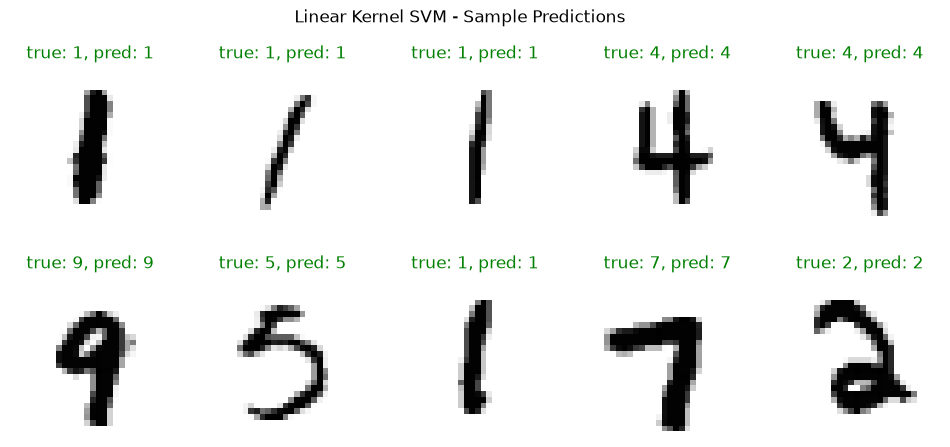

In [23]:
plt.figure(figsize=(12, 5))

for i in range(10):
    image = X_test[i].reshape(28, 28)
    true_label = int(y_test[i])
    predicted_label = int(y_predicted[i])

    plt.subplot(2, 5, i + 1)
    plt.imshow(image, cmap='gray')
    plt.axis('off')

    if true_label == predicted_label:
        plt.title("true: " + str(true_label) + ", pred: " + str(predicted_label), color='green')
    else:
        plt.title("true: " + str(true_label) + ", pred: " + str(predicted_label), color='red')

plt.suptitle("Linear Kernel SVM - Sample Predictions")
plt.show()

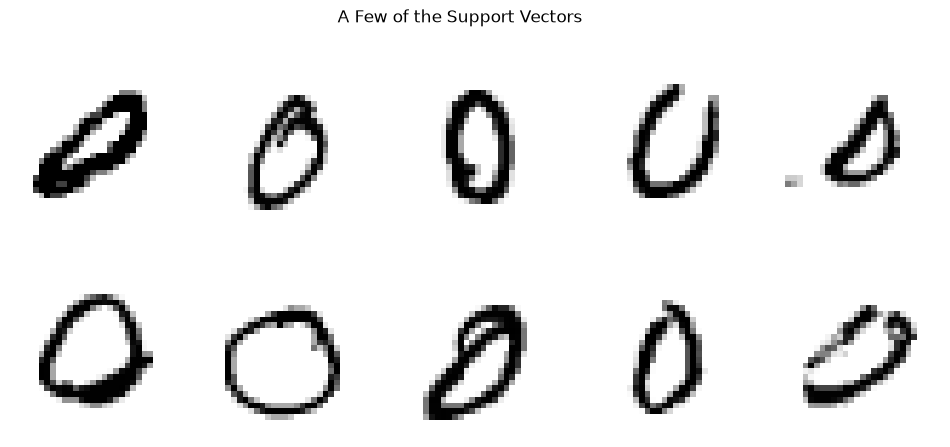

In [24]:
plt.figure(figsize=(12, 5))

for i in range(10):
    sv_image = model.support_vectors_[i].reshape(28, 28)

    plt.subplot(2, 5, i + 1)
    plt.imshow(sv_image, cmap='gray')
    plt.axis('off')

plt.suptitle("A Few of the Support Vectors")
plt.show()